# Train: Logistic Regression on the 200k Dataset (cmu + synthetic)

## 1. Introduction

This is step 3 (**Train**) of the five-step workflow, for the model trained on the 200k set from `01_prepare_synthetic`. The test set is **not opened** in this notebook. We repeat the steps of the 70k model so that the two models can be compared fairly:

1. Load the training set and define X and y.
2. Train **baseline models**.
3. Choose the features, using training data only.
4. Train the logistic regression and report its **training score**.
5. Estimate how well it will do on new people with **5-fold cross-validation**.
6. Choose the **decision threshold** for our Recall goal.
7. Save the model.

### The problem that synthetic data creates for cross-validation
The 70k notebook used ordinary cross-validation. That would be **wrong here**. A synthetic row is an interpolation between real people. If a synthetic row sits in the training part of a fold and the real person it was built from sits in the validation part, the model has effectively seen that person, and the score is too good.

The fix has three parts:

| Rule | Why |
|---|---|
| **Validate on real rows only** | Synthetic rows are never used to score a model |
| **Split the real rows into folds first** | The real people are divided before any synthetic row exists |
| **Create the synthetic rows inside each fold, from the training part only** | No synthetic row can be built from a validation person |

So in every fold the model is trained on real rows + synthetic rows made from those real rows, and scored on real people it has never seen, in the same way as the final model will be scored on the test set.

### Metrics on a 50/50 scale
The real validation rows are not 50/50 (the real no-diabetes rows outnumber the diabetes rows about 3.6 to 1). **Recall, specificity and ROC AUC do not depend on the mix**, and from them we compute precision, F1 and accuracy *as if* the validation data were 50/50. This puts every score on the same scale as the 70k notebooks and the balanced test set.

**Source table:** `diabetes_cmu_synth_train` | **Output:** a saved model file

## 2. Import Libraries and Connect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
import sklearn

# statsmodels: p-values for the feature selection
import statsmodels.api as sm

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sqlalchemy import create_engine, text

# Our own helper file in this folder (creates the synthetic rows)
from synth_utils import generate_synthetic

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

TRAIN_TABLE = "diabetes_cmu_synth_train"
TARGET = "Diabetes_binary"
RANDOM_STATE = 42
TARGET_RECALL = 0.85              # PLACEHOLDER: same working goal as the 70k model (the group should confirm it)
REAL_PREVALENCE = 0.14            # about 14% of the surveyed people had diabetes
MODEL_PATH = Path("../../application/models/logreg_200k.joblib")

with engine.connect() as conn:
    conn.execute(text("SELECT 1"))

print("Libraries imported and database connection successful.")

Libraries imported and database connection successful.


## 3. Load the Training Set

In [2]:
train_df = pd.read_sql(f"SELECT * FROM {TRAIN_TABLE}", con=engine)

all_features = [c for c in train_df.columns if c not in (TARGET, "is_synthetic")]
X_train, y_train = train_df[all_features], train_df[TARGET]

# The real rows only (used for cross-validation and for the p-values)
real_df = train_df[train_df["is_synthetic"] == 0].reset_index(drop=True)
X_real, y_real = real_df[all_features], real_df[TARGET]

NON_BINARY = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]

summary = pd.DataFrame({
    "Item": ["Training rows", "Features", "No diabetes (0)", "Diabetes (1)",
             "Real rows", "Real: no diabetes", "Real: diabetes", "Synthetic rows (all diabetes)"],
    "Value": [f"{len(train_df):,}", len(all_features), f"{(y_train == 0).sum():,}", f"{(y_train == 1).sum():,}",
              f"{len(real_df):,}", f"{(y_real == 0).sum():,}", f"{(y_real == 1).sum():,}",
              f"{int(train_df['is_synthetic'].sum()):,}"],
})
display(summary.style.hide(axis="index"))

print(f"Training set '{TRAIN_TABLE}' loaded successfully.")

Item,Value
Training rows,"200,000"
Features,21
No diabetes (0),"100,000"
Diabetes (1),"100,000"
Real rows,"128,078"
Real: no diabetes,"100,000"
Real: diabetes,"28,078"
Synthetic rows (all diabetes),"71,922"


Training set 'diabetes_cmu_synth_train' loaded successfully.


## 4. Tools Used in This Notebook

- **Cross-validation folds (real rows only, synthetic rows made inside each fold).** The folds are built **once** and reused for every model, so all models are scored on exactly the same people.
- **Model builder:** the same as for the 70k model: logistic regression with no penalty, the 7 non-binary features standardized inside the model.
- **Metrics on a 50/50 scale:** Recall, specificity and ROC AUC are measured directly. Precision, F1 and accuracy are computed from Recall and the false alarm rate as if the people with and without diabetes were equally many.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_logreg(cols):
    """Logistic regression (no penalty) with scaling of the non-binary columns done inside the model."""
    scale = [c for c in cols if c in NON_BINARY]
    prep = ColumnTransformer([("scale", StandardScaler(), scale)],
                             remainder="passthrough", verbose_feature_names_out=False)
    return Pipeline([("prep", prep), ("model", LogisticRegression(C=np.inf, max_iter=2000))])

def scores_5050(y, proba, t=0.5):
    """Metrics for one set of rows, with precision/F1/accuracy on a 50/50 scale."""
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    tpr, tnr = tp / (tp + fn), tn / (tn + fp)
    prec = tpr / (tpr + (1 - tnr)) if (tpr + (1 - tnr)) > 0 else 0.0
    f1 = 2 * prec * tpr / (prec + tpr) if (prec + tpr) > 0 else 0.0
    return {"Accuracy": (tpr + tnr) / 2, "Recall": tpr, "Specificity": tnr,
            "Precision": prec, "F1": f1, "ROC AUC": roc_auc_score(y, proba)}

# --- Build the 5 folds ONCE: split the real rows, then create synthetic rows from each training part ---
folds = []
for i, (tr, va) in enumerate(cv.split(X_real, y_real)):
    X_tr, y_tr = X_real.iloc[tr], y_real.iloc[tr]
    X_va, y_va = X_real.iloc[va], y_real.iloc[va]
    n_new = int((y_tr == 0).sum() - (y_tr == 1).sum())                 # make the training part 50/50
    syn = generate_synthetic(X_tr[y_tr == 1], n_new, seed=RANDOM_STATE + i, avoid=X_va)
    folds.append({
        "X_tr": pd.concat([X_tr, syn], ignore_index=True),
        "y_tr": pd.concat([y_tr, pd.Series(1, index=range(n_new))], ignore_index=True),
        "X_va": X_va, "y_va": y_va,
    })

def cv_scores(build_model, cols):
    """Mean and standard deviation of every metric over the 5 folds (validation rows are real)."""
    rows = []
    for f in folds:
        model = build_model(cols).fit(f["X_tr"][cols], f["y_tr"])
        rows.append(scores_5050(f["y_va"], model.predict_proba(f["X_va"][cols])[:, 1]))
    res = pd.DataFrame(rows)
    return {m: (res[m].mean(), res[m].std()) for m in res.columns}

fold_info = pd.DataFrame({
    "Fold": range(1, 6),
    "Training rows (real + synthetic)": [f"{len(f['X_tr']):,}" for f in folds],
    "of which synthetic": [f"{len(f['X_tr']) - (len(X_real) - len(f['X_va'])):,}" for f in folds],
    "Validation rows (all real)": [f"{len(f['X_va']):,}" for f in folds],
    "Validation: % diabetes": [f"{f['y_va'].mean() * 100:.1f}%" for f in folds],
})
display(fold_info.style.hide(axis="index"))

print("Tools defined and the 5 cross-validation folds built.")

Fold,Training rows (real + synthetic),of which synthetic,Validation rows (all real),Validation: % diabetes
1,"160,000","57,538","25,616",21.9%
2,"160,000","57,538","25,616",21.9%
3,"160,000","57,538","25,616",21.9%
4,"160,000","57,537","25,615",21.9%
5,"160,000","57,537","25,615",21.9%


Tools defined and the 5 cross-validation folds built.


## 5. Baseline Models

The same three baselines as for the 70k model. They are trained on each fold's training part and scored on the real validation people. All three use no information from the features, so every one should sit at chance.

In [4]:
baselines = {
    "Baseline: always no diabetes": lambda cols: DummyClassifier(strategy="constant", constant=0),
    "Baseline: flag everybody": lambda cols: DummyClassifier(strategy="constant", constant=1),
    "Baseline: random guess": lambda cols: DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}

baseline_cv = {name: cv_scores(b, all_features) for name, b in baselines.items()}

table = pd.DataFrame({
    name: {m: f"{mean:.3f} ± {sd:.3f}" for m, (mean, sd) in scores.items()}
    for name, scores in baseline_cv.items()
}).T
display(table)

print("Baselines trained successfully.")

,Accuracy,Recall,Specificity,Precision,F1,ROC AUC
Baseline: always no diabetes,0.500 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Baseline: flag everybody,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.667 ± 0.000,0.500 ± 0.000
Baseline: random guess,0.502 ± 0.004,0.501 ± 0.006,0.503 ± 0.002,0.502 ± 0.004,0.502 ± 0.005,0.502 ± 0.004


Baselines trained successfully.


**Interpretation:** All three baselines sit at chance. Their ROC AUC is 0.500, 0.500 and 0.502, and accuracy is 0.500, 0.500 and 0.502. *Always no diabetes* has Recall 0.000 (it finds nobody) and *flag everybody* has Recall 1.000 but Precision 0.500 (it is wrong half of the time). The random guess is about 0.50 on everything, with a standard deviation of only 0.004 to 0.006, so the folds are stable. Note that *flag everybody* has an F1 of 0.667 even though it uses no information, so F1 alone can look good for a useless model. The real model must beat 0.50 on ROC AUC and 0.667 on F1.

## 6. Feature Selection (Training Data Only)

The same three candidate sets and the same rule as in the 70k notebook, fixed before looking at the results:

| Candidate | Features |
|---|---|
| All features | 21 |
| Without healthcare access | 18 (drops `CholCheck`, `AnyHealthcare`, `NoDocbcCost`) |
| p-value rule | the features with p <= 0.05 |

**Selection rule:** the smallest set whose cross-validated ROC AUC is within one standard deviation of the best.

**The p-values are fitted on the real training rows only.** The synthetic rows are not independent people: each one is built from real rows, so using them would make the effects look more certain than they are (the p-values would be too small). The coefficients of a logistic regression do not depend on the class mix, so the real rows (which are not 50/50) give valid p-values.

In [5]:
# --- p-value rule, fitted on the REAL training rows only ---
scaled = X_real.astype(float).copy()
scaled[NON_BINARY] = StandardScaler().fit_transform(scaled[NON_BINARY])
sm_fit = sm.Logit(y_real, sm.add_constant(scaled)).fit(disp=False)
p_values = sm_fit.pvalues.drop("const")

p_table = pd.DataFrame({
    "p-value (real training rows)": p_values.round(3),
    "Kept by the rule (p <= 0.05)": p_values <= 0.05,
}).sort_values("p-value (real training rows)", ascending=False)
display(p_table)

# --- Candidate feature sets ---
feature_sets = {
    "All features (21)": all_features,
    "Without healthcare access (18)": [f for f in all_features if f not in ["CholCheck", "AnyHealthcare", "NoDocbcCost"]],
    "p-value rule (real training rows)": [f for f in all_features if p_values[f] <= 0.05],
}
print("Dropped by the p-value rule:", [f for f in all_features if p_values[f] > 0.05])

# --- Score every candidate with the 5 folds (ROC AUC) ---
rows = []
for name, cols in feature_sets.items():
    s = cv_scores(make_logreg, cols)["ROC AUC"]
    rows.append({"Feature set": name, "Features": len(cols), "ROC AUC (mean)": s[0], "ROC AUC (std)": s[1]})
fs = pd.DataFrame(rows)

# --- Selection rule: the smallest set within one standard deviation of the best ---
best = fs.loc[fs["ROC AUC (mean)"].idxmax()]
within = fs[fs["ROC AUC (mean)"] >= best["ROC AUC (mean)"] - best["ROC AUC (std)"]]
chosen_name = within.sort_values(["Features", "ROC AUC (mean)"], ascending=[True, False]).iloc[0]["Feature set"]
fs["Within 1 SD of the best"] = fs["Feature set"].isin(within["Feature set"])
fs["Chosen"] = fs["Feature set"] == chosen_name
display(fs.round(4).style.hide(axis="index"))

# To override the rule by group decision, set chosen_name by hand, for example:
# chosen_name = "All features (21)"      # (use the same feature set as the 70k model for a cleaner comparison)
FEATURES = feature_sets[chosen_name]
print(f"Chosen feature set: {chosen_name} ({len(FEATURES)} features)")
print("Features:", ", ".join(FEATURES))

,p-value (real training rows),Kept by the rule (p <= 0.05)
Veggies,0.463,False
NoDocbcCost,0.243,False
Smoker,0.178,False
Fruits,0.080,False
PhysActivity,0.016,True
Education,0.006,True
AnyHealthcare,0.002,True
HighChol,0.000,True
HighBP,0.000,True
Stroke,0.000,True


Dropped by the p-value rule: ['Smoker', 'Fruits', 'Veggies', 'NoDocbcCost']


Feature set,Features,ROC AUC (mean),ROC AUC (std),Within 1 SD of the best,Chosen
All features (21),21,0.807900,0.006200,True,False
Without healthcare access (18),18,0.806400,0.006300,True,False
p-value rule (real training rows),17,0.807900,0.006300,True,True


Chosen feature set: p-value rule (real training rows) (17 features)
Features: HighBP, HighChol, CholCheck, Stroke, HeartDiseaseorAttack, PhysActivity, HvyAlcoholConsump, AnyHealthcare, DiffWalk, Sex, BMI, GenHlth, MentHlth, PhysHlth, Age, Education, Income


**Interpretation:** The p-value rule drops 4 features: `Veggies` (p = 0.463), `NoDocbcCost` (0.243), `Smoker` (0.178) and `Fruits` (0.080). All the others are significant, including `PhysActivity` (0.016), `Education` (0.006) and `AnyHealthcare` (0.002). The three candidate sets are almost identical in ROC AUC: 0.8079 for all 21 features, 0.8064 without healthcare access (18) and 0.8079 for the p-value rule (17), each with a standard deviation of about 0.006. All three are within one standard deviation of the best, so the rule picks the smallest set, the **p-value rule with 17 features**. Dropping the four features costs nothing, while dropping the healthcare access features costs a little (0.0015, within the noise). Compared with the 70k model, which dropped `Veggies`, `Smoker`, `NoDocbcCost`, `PhysActivity` and `Education` (16 features left), the 200k model keeps `PhysActivity` and `Education`. A likely reason is that the p-values here use 128,078 real rows instead of 56,155, so smaller effects become detectable. The two models therefore differ in their features as well as in their data, and this must be stated in `08_model_comparison`.

## 7. Train the Logistic Regression

We fit the model on the whole 200k training set (real + synthetic) with the chosen features: **fit**, then **predict**, then **score**. The training score is reported twice: on all 200,000 rows, and on the **real rows only**, which is the fairer one because the model has seen the synthetic rows' parents anyway.

In [6]:
logreg = make_logreg(FEATURES)
logreg.fit(X_train[FEATURES], y_train)

proba_all = logreg.predict_proba(X_train[FEATURES])[:, 1]
is_real = (train_df["is_synthetic"] == 0).to_numpy()

logreg_train = {"All 200,000 rows": scores_5050(y_train, proba_all),
                "Real rows only": scores_5050(y_train[is_real], proba_all[is_real])}
display(pd.DataFrame(logreg_train).round(3))

# Odds ratios of the final model
names = logreg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=names)
odds = pd.DataFrame({"Odds ratio": np.exp(coefs)}).sort_values("Odds ratio", ascending=False).round(3)
display(odds)

print("Logistic regression trained successfully.")

,"All 200,000 rows",Real rows only
Accuracy,0.746,0.732
Recall,0.766,0.738
Specificity,0.727,0.727
Precision,0.737,0.730
F1,0.751,0.734
ROC AUC,0.823,0.808


,Odds ratio
CholCheck,4.690
HighBP,2.101
GenHlth,1.902
HighChol,1.811
BMI,1.710
Age,1.470
Sex,1.304
AnyHealthcare,1.265
HeartDiseaseorAttack,1.196
DiffWalk,1.151


Logistic regression trained successfully.


For the standardized features, an odds ratio means "per 1 standard deviation increase". For the 0/1 features it means "Yes compared with No". The "Real rows only" column is on a 50/50 scale (see section 1).

**Interpretation:** On the real training rows, the model reaches a ROC AUC of 0.808, a Recall of 0.738 and an accuracy of 0.732 (50/50 scale). On all 200,000 rows the scores are higher (ROC AUC 0.823, Recall 0.766, accuracy 0.746), because the synthetic rows are easier to fit than real people. We therefore trust the "Real rows only" column. **Odds ratios:** the strongest are `CholCheck` (4.69), `HighBP` (2.10), `GenHlth` (1.90 per standard deviation), `HighChol` (1.81), `BMI` (1.71 per standard deviation), `Age` (1.47) and `Sex` (1.30, male against female). Higher `Income` lowers the odds (0.873 per standard deviation). These directions make sense. Two results need care. First, `CholCheck` is not a cause of diabetes. It is a proxy: nearly everybody with diabetes has had a cholesterol check (99.3%), so the model uses it as a signal, and almost every synthetic diabetes row copies this (99.5%), which probably makes its odds ratio larger than the real data alone would give. Second, `HvyAlcoholConsump` has an odds ratio of 0.380, which would mean heavy drinking protects against diabetes. This is not true advice. It is a survey effect (people with diabetes are told to stop drinking, and the data shows who is drinking *now*), and the app must never present it as a benefit. Features with odds ratios close to 1 (`Stroke`, `MentHlth`, `PhysActivity`, `PhysHlth`, `Education`) add little on their own.

## 8. Model Comparison: Logistic Regression Against the Baselines

The cross-validation scores are honest: real validation people, synthetic rows made inside each fold. We compare them with the training scores to check for overfitting.

In [7]:
logreg_cv = cv_scores(make_logreg, FEATURES)

all_cv = {**baseline_cv, "Logistic regression": logreg_cv}
cv_table = pd.DataFrame({
    name: {m: f"{mean:.3f} ± {sd:.3f}" for m, (mean, sd) in scores.items()}
    for name, scores in all_cv.items()
}).T
print("Cross-validation scores (real validation people, 50/50 scale):")
display(cv_table)

gap = pd.DataFrame({
    "Training score (real rows)": pd.Series(logreg_train["Real rows only"]),
    "Cross-validation score": pd.Series({m: v[0] for m, v in logreg_cv.items()}),
})
gap["Gap (training - CV)"] = gap["Training score (real rows)"] - gap["Cross-validation score"]
print("Logistic regression: training vs cross-validation")
display(gap.round(4))

beats = all(logreg_cv["ROC AUC"][0] > b["ROC AUC"][0] for b in baseline_cv.values())
print("Logistic regression beats every baseline on ROC AUC:", beats)

Cross-validation scores (real validation people, 50/50 scale):


,Accuracy,Recall,Specificity,Precision,F1,ROC AUC
Baseline: always no diabetes,0.500 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Baseline: flag everybody,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.667 ± 0.000,0.500 ± 0.000
Baseline: random guess,0.502 ± 0.004,0.501 ± 0.006,0.503 ± 0.002,0.502 ± 0.004,0.502 ± 0.005,0.502 ± 0.004
Logistic regression,0.732 ± 0.005,0.738 ± 0.008,0.727 ± 0.004,0.730 ± 0.004,0.734 ± 0.006,0.808 ± 0.006


Logistic regression: training vs cross-validation


,Training score (real rows),Cross-validation score,Gap (training - CV)
Accuracy,0.7325,0.7324,0.0000
Recall,0.7383,0.7383,0.0000
Specificity,0.7266,0.7266,0.0000
Precision,0.7298,0.7297,0.0001
F1,0.7340,0.7340,0.0001
ROC AUC,0.8081,0.8079,0.0002


Logistic regression beats every baseline on ROC AUC: True


**Interpretation:** In cross-validation on real validation people the logistic regression reaches Accuracy 0.732, Recall 0.738, Specificity 0.727, Precision 0.730, F1 0.734 and ROC AUC 0.808 (standard deviation 0.006), against about 0.50 for every baseline. It beats all three baselines. The gap between the training score on real rows and the cross-validation score is practically zero (0.0000 to 0.0002), so there is **no overfitting**: a 17-feature logistic regression on 128,078 real rows is too simple to memorise the data. It also tells us the model is limited by the information in the survey answers, not by how it was trained, so a more complex model would not fix the 0.81 ROC AUC by itself. A training score that is *not* better than the CV score also supports that the fold procedure has no leakage.

## 9. Choosing the Decision Threshold for Recall

Same idea as for the 70k model: pick the **highest threshold that still reaches the Recall goal**, using predictions that come from models that did not see the person (**out-of-fold** predictions). Here the out-of-fold predictions are for the **real** validation people of the 5 folds, so the threshold is not influenced by synthetic rows.

Because Recall and the false alarm rate do not depend on the class mix, they can be read directly from these real people. The precision at the real prevalence (about 14%) is estimated from them, as before. It is an approximation, because the labels are self-reported diagnoses.

Setting,Threshold,Recall,Specificity,Precision (50/50 scale),Precision at 14% prevalence,Share of people flagged at 14%
Default threshold,0.500000,0.738000,0.727000,0.730000,0.305000,0.339000
Recall goal 70%,0.535000,0.700000,0.757000,0.742000,0.319000,0.307000
Recall goal 80%,0.436000,0.800000,0.668000,0.706000,0.281000,0.398000
Recall goal 85%,0.379000,0.850000,0.608000,0.685000,0.261000,0.456000
Recall goal 90%,0.312000,0.900000,0.532000,0.658000,0.238000,0.528000


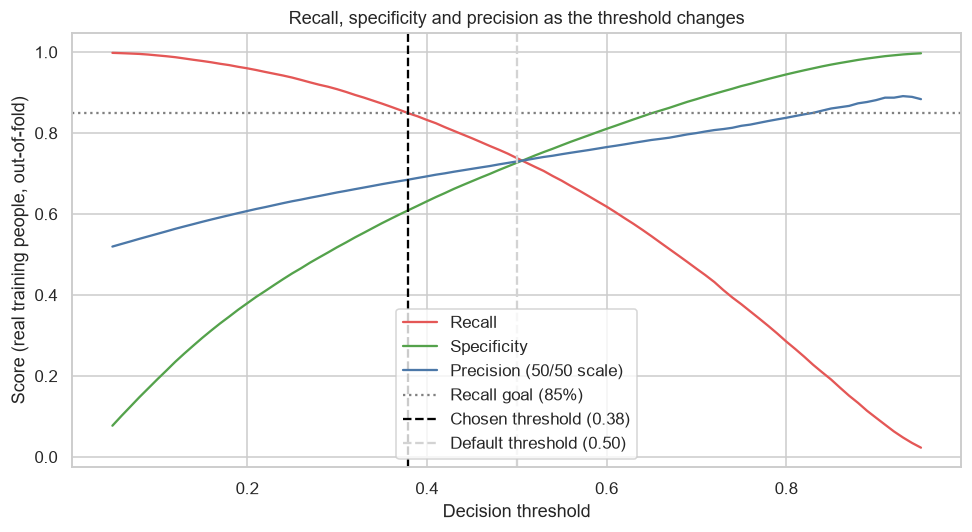

Chosen threshold: 0.379 (reaches a Recall of at least 85% out-of-fold).


In [8]:
# Out-of-fold probabilities for every real training person
oof_p, oof_y = [], []
for f in folds:
    model = make_logreg(FEATURES).fit(f["X_tr"][FEATURES], f["y_tr"])
    oof_p.append(model.predict_proba(f["X_va"][FEATURES])[:, 1])
    oof_y.append(f["y_va"].to_numpy())
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)

def threshold_for(goal):
    """Highest threshold at which at least `goal` of the people with diabetes are flagged."""
    return float(np.quantile(oof_p[oof_y == 1], 1 - goal, method="lower"))

def metrics_at(t):
    flagged = oof_p >= t
    tpr, fpr = flagged[oof_y == 1].mean(), flagged[oof_y == 0].mean()
    flagged_real = tpr * REAL_PREVALENCE + fpr * (1 - REAL_PREVALENCE)
    return {"Recall": tpr, "Specificity": 1 - fpr,
            "Precision (50/50 scale)": tpr / (tpr + fpr),
            f"Precision at {REAL_PREVALENCE:.0%} prevalence": tpr * REAL_PREVALENCE / flagged_real,
            f"Share of people flagged at {REAL_PREVALENCE:.0%}": flagged_real}

rows = [{"Setting": "Default threshold", "Threshold": 0.5, **metrics_at(0.5)}]
for goal in [0.70, 0.80, 0.85, 0.90]:
    t = threshold_for(goal)
    rows.append({"Setting": f"Recall goal {goal:.0%}", "Threshold": t, **metrics_at(t)})
goals = pd.DataFrame(rows)
display(goals.round(3).style.hide(axis="index"))

chosen_threshold = threshold_for(TARGET_RECALL)

# Chart: recall, specificity and precision as the threshold changes
grid = np.linspace(0.05, 0.95, 91)
curve = pd.DataFrame([metrics_at(t) for t in grid], index=grid)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(grid, curve["Recall"], label="Recall", color="#E45756")
ax.plot(grid, curve["Specificity"], label="Specificity", color="#54A24B")
ax.plot(grid, curve["Precision (50/50 scale)"], label="Precision (50/50 scale)", color="#4C78A8")
ax.axhline(TARGET_RECALL, ls=":", color="grey", label=f"Recall goal ({TARGET_RECALL:.0%})")
ax.axvline(chosen_threshold, ls="--", color="black", label=f"Chosen threshold ({chosen_threshold:.2f})")
ax.axvline(0.5, ls="--", color="lightgrey", label="Default threshold (0.50)")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score (real training people, out-of-fold)")
ax.set_title("Recall, specificity and precision as the threshold changes")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Chosen threshold: {chosen_threshold:.3f} (reaches a Recall of at least {TARGET_RECALL:.0%} out-of-fold).")

**Interpretation:** The chosen threshold for a Recall goal of 85% is **0.379**. It reaches a Recall of 0.850 out-of-fold with a specificity of 0.608, a precision of 0.685 on the 50/50 scale, and 0.261 at the real prevalence of 14%. At that prevalence 45.6% of all people would be flagged. Compared with the default threshold of 0.50 (Recall 0.738, specificity 0.727), we gain 11 points of Recall and pay 12 points of specificity. At the real prevalence only about 1 in 4 flagged people really has diabetes, which is normal for a screening test whose follow-up is a cheap blood test. A goal of 90% would flag 52.8% of people (threshold 0.312), and a goal of 70% would miss 3 in 10 people with diabetes, so 85% is a reasonable middle. The 70k model had almost the same result (threshold 0.40, specificity 0.610, about 45.5% flagged), so the extra data did not change what the threshold costs.

## 10. Save the Model

In [9]:
bundle = {
    "model": logreg,
    "features": FEATURES,
    "threshold": chosen_threshold,
    "target_recall": TARGET_RECALL,
    "feature_set_name": chosen_name,
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
    "training_data": "200k: 100,000 no diabetes (real) + 100,000 diabetes (real + synthetic)",
}
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(bundle, MODEL_PATH)

# Verify: reload the file and check that it gives identical predictions
reloaded = joblib.load(MODEL_PATH)
same = np.allclose(reloaded["model"].predict_proba(X_train[FEATURES])[:, 1],
                   logreg.predict_proba(X_train[FEATURES])[:, 1])

saved = pd.DataFrame({
    "Item": ["File", "Features saved", "Threshold saved", "scikit-learn version", "Reloaded model gives identical predictions"],
    "Value": [str(MODEL_PATH), len(reloaded["features"]), round(reloaded["threshold"], 3),
              reloaded["sklearn_version"], same],
})
display(saved.style.hide(axis="index"))

print("Model saved successfully.")

Item,Value
File,..\..\application\models\logreg_200k.joblib
Features saved,17
Threshold saved,0.379000
scikit-learn version,1.9.1
Reloaded model gives identical predictions,True


Model saved successfully.


## 11. Summary

**What we did in this notebook**
1. Loaded the 200k training set (200,000 rows: 128,078 real, 71,922 synthetic). The test set was not opened.
2. Built 5 cross-validation folds from the **real** rows, creating synthetic rows inside each fold, so that no validation person leaks into training.
3. Trained three baselines.
4. Compared three candidate feature sets (p-values from real rows only) and chose the p-value rule (17 features).
5. Trained the logistic regression, and compared training with cross-validation scores.
6. Chose the decision threshold for the Recall goal, using out-of-fold predictions for real people.
7. Saved the model, its features and its threshold as `logreg_200k.joblib`.

**Key results**
- **Baselines (ROC AUC / Recall):** all three at chance: ROC AUC 0.500 / 0.500 / 0.502, Recall 0.000 / 1.000 / 0.501.
- **Feature sets:** ROC AUC 0.8079 (21 features), 0.8064 (18) and 0.8079 (17), all within one standard deviation across the three sets; chosen: the p-value rule with 17 features.
- **Logistic regression (cross-validation, 50/50 scale):** Recall 0.738, Precision 0.730, F1 0.734, ROC AUC 0.808. Gap between training and cross-validation: practically zero (0.0002 in ROC AUC), so no overfitting.
- **Threshold:** 0.379 for a Recall goal of 85%.

**Decisions carried forward**
- Recall goal 85% is the same working goal as for the 70k model, so the two thresholds can be compared.
- `03_evaluate` loads `logreg_200k.joblib` and predicts on the same real test set as the 70k model.

**Limitations**
- Cross-validation scores are on a 50/50 scale computed from real validation people, so precision and accuracy are estimates of what a balanced test set would show.
- The synthetic rows carry no new information (see `01_prepare_synthetic`).

**Next step:** `03_evaluate`.